# 01. Business Understanding

### 1. Problem Statement:
A telecommunications company is facing revenue loss due to customer churn. The goal is to build a machine learning classification model to identify customers who are likely to leave, enabling the marketing and customer retention teams to intervene proactively before the customer cancels their subscription.

### 2. Target Variable & Problem Type:
- **Target Column:** `Churn` (Binary: 'Yes' or 'No').
- **Problem Type:** Supervised Binary Classification, because we are predicting a discrete categorical outcome for each customer.

### 3. Business Use Cases:
1. **Targeted Retention Campaigns:** Offering customized discounts, bundles, or incentives to high-risk customers.
2. **Customer Service Intervention:** Escalating service complaints from high-risk accounts to senior support managers.

### 4. Cost of False Negatives:
Missing a customer who actually intends to churn (**False Negative**) is significantly more costly than targeting a customer who wasn't going to leave (**False Positive**), because the customer acquisition cost (CAC) in telecommunications is typically 5x to 7x higher than retention costs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv('Telco-Customer-Churn.csv')

In [4]:
print(f"Dataset Shape: {df.shape}")
display(df.head())
print("\n--- Data Info ---")
df.info()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 

In [5]:
print("\n--- Missing Values Check ---")
print(df.isnull().sum())

print("\nEmpty strings in TotalCharges:", (df['TotalCharges'].str.strip() == '').sum())
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')


--- Missing Values Check ---
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Empty strings in TotalCharges: 11


C:\Users\a0597\AppData\Local\Temp\ipykernel_53532\151387083.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', ax=axes[0, 0], palette='pastel')
C:\Users\a0597\AppData\Local\Temp\ipykernel_53532\151387083.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='tenure', ax=axes[1, 0], palette='Set2')


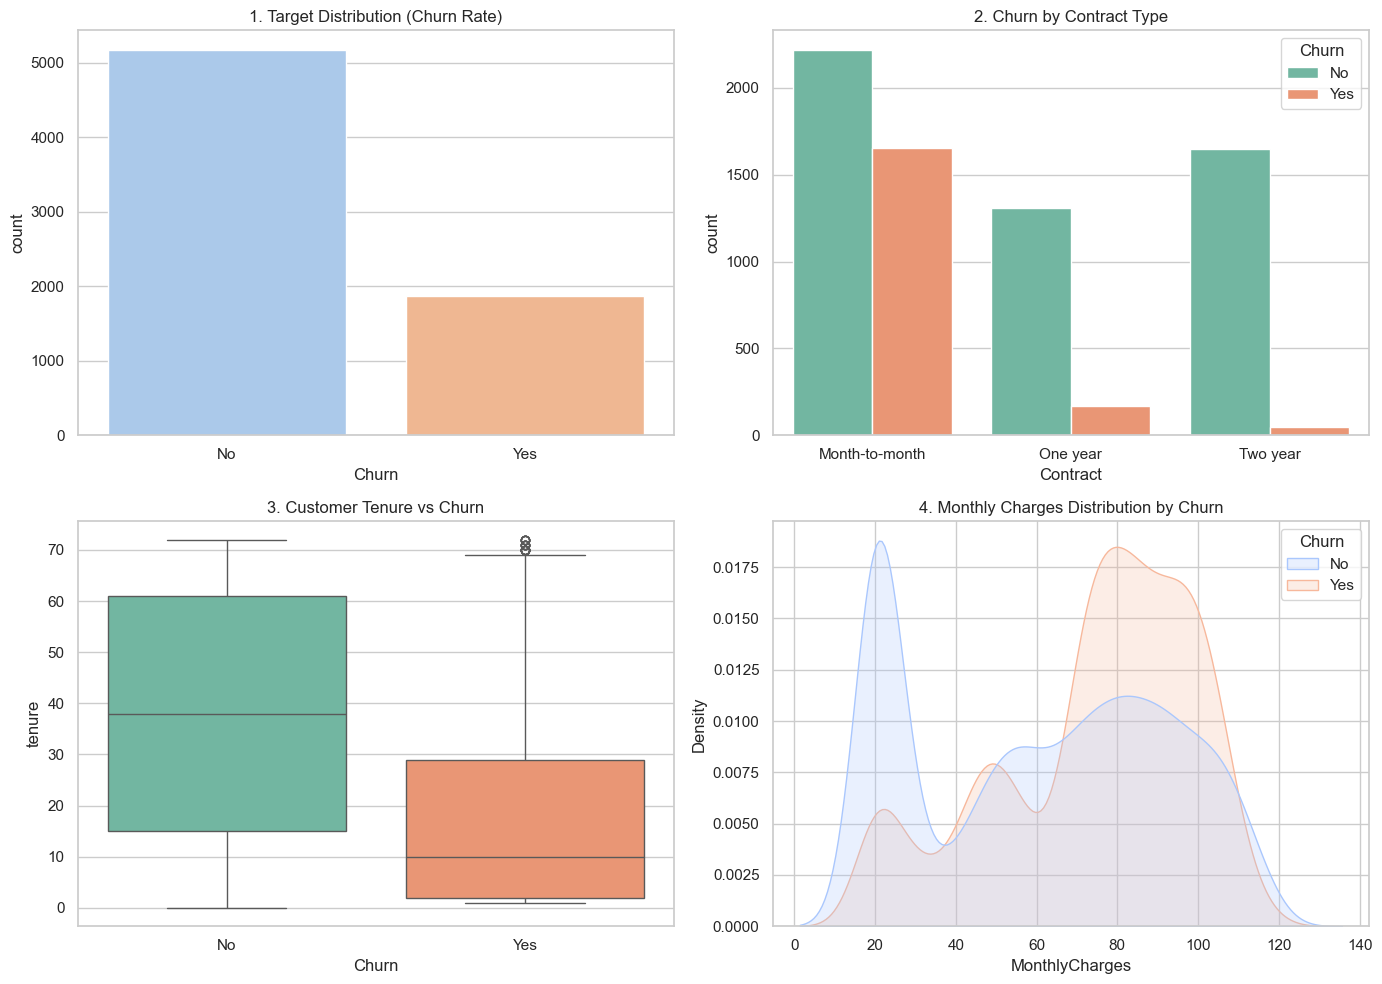

In [8]:
# 3.(EDA - 4 Charts)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: Target Distribution (Class Imbalance)
sns.countplot(data=df, x='Churn', ax=axes[0, 0], palette='pastel')
axes[0, 0].set_title('1. Target Distribution (Churn Rate)')

# Chart 2: Churn by Contract Type
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('2. Churn by Contract Type')

# Chart 3: Tenure Distribution by Churn
sns.boxplot(data=df, x='Churn', y='tenure', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('3. Customer Tenure vs Churn')

# Chart 4: Monthly Charges vs Churn
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, common_norm=False, ax=axes[1, 1], palette='coolwarm')
axes[1, 1].set_title('4. Monthly Charges Distribution by Churn')

plt.tight_layout()
plt.show()

### Key EDA Findings & Insights:
1. **Class Imbalance:** Around 26.5% of customers churned. This indicates an imbalanced dataset, meaning Accuracy alone won't be a reliable metric; Recall and F1-Score for the Churn class will be crucial.
2. **Contract Type Impact:** Customers with a **Month-to-month** contract have a significantly higher churn rate compared to those with One-year or Two-year contracts. Long-term contracts strongly retain customers.
3. **Customer Tenure:** Churn is heavily concentrated among newer customers with low tenure (first few months). Retention risk decreases substantially as tenure increases.
4. **Monthly Charges:** Customers with higher monthly charges (especially around $70–$100) are more prone to leaving compared to customers on low-cost plans.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

In [10]:
df_clean = df.drop(columns=['customerID'])

In [11]:
X = df_clean.drop(columns=['Churn'])
y = df_clean['Churn'].map({'Yes': 1, 'No': 0})

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [13]:
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

In [15]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

print(f"Train set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print("Numerical columns:", numerical_cols)
print("Categorical columns count:", len(categorical_cols))
print("\n✅ Preprocessing Pipeline is ready with no Data Leakage!")

Train set size: 5634 samples
Test set size: 1409 samples
Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns count: 15

✅ Preprocessing Pipeline is ready with no Data Leakage!


In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

In [18]:
# 1. Define models with 'balanced' class weights to handle dataset imbalance
models = {
    'Baseline (Dummy)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(random_state=42, class_weight='balanced'),
    'Support Vector Machine': SVC(random_state=42, class_weight='balanced')
}

results = []

# 2. Train each model, make predictions, and extract evaluation metrics
for name, clf in models.items():
    # Build the Pipeline combining preprocessing and the classifier
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', clf)])
    
    # Train the model
    pipe.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = pipe.predict(X_test)
    
    # Calculate metrics and append to results list
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (Churn)': precision_score(y_test, y_pred, zero_division=0),
        'Recall (Churn)': recall_score(y_test, y_pred),
        'F1-score (Churn)': f1_score(y_test, y_pred)
    })

# 3. Create a DataFrame for results and highlight the best values for Recall and F1-score
results_df = pd.DataFrame(results)
display(results_df.style.highlight_max(subset=['Recall (Churn)', 'F1-score (Churn)'], color='lightgreen'))

,Model,Accuracy,Precision (Churn),Recall (Churn),F1-score (Churn)
0,Baseline (Dummy),0.734564,0.000000,0.000000,0.000000
1,Logistic Regression,0.738112,0.504303,0.783422,0.613613
2,Random Forest,0.782115,0.618375,0.467914,0.532725
3,Support Vector Machine,0.743790,0.511504,0.772727,0.615548


In [19]:
from sklearn.model_selection import GridSearchCV

In [20]:
# 1. Define hyperparameter grid for Random Forest
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [5, 10, None],
    'classifier__min_samples_split': [2, 10]
}

In [21]:
# 2. Setup Pipeline with Random Forest
rf_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

In [22]:
# 3. Apply GridSearchCV focusing on 'recall' optimization
grid_search = GridSearchCV(
    estimator=rf_pipe,
    param_grid=param_grid,
    cv=5,
    scoring='recall',  # Optimizing for Recall based on business understanding
    n_jobs=-1
)

In [25]:
# Train the GridSearch
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['SeniorCitizen',
                                                                          'tenure',
                                                                          'MonthlyCharges',
                                                                          'TotalCharges']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(h...
                                                                          'OnlineBackup',
                                                                          'DeviceProtection',
                                                                          'TechSupport',
                                                                          'StreamingTV',
                                                                          'StreamingMovies',
                                                                          'Contract',
                                                                          'PaperlessBilling',
                                                                          'PaymentMethod'])])),
                                       ('classifier',
                                        RandomForestClassifier(class_weight='balanced',
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__max_depth': [5, 10, None],
                         'classifier__min_samples_split': [2, 10],
                         'classifier__n_estimators': [100, 200]},
             scoring='recall')

In [26]:
# 4. Extract the best model and parameters
best_rf_model = grid_search.best_estimator_
print("Best Hyperparameters:", grid_search.best_params_)

Best Hyperparameters: {'classifier__max_depth': 5, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}


In [27]:
# 5. Evaluate the tuned model on the Test set
y_pred_tuned = best_rf_model.predict(X_test)

print("\n--- Tuned Random Forest Evaluation ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_tuned):.4f}")


--- Tuned Random Forest Evaluation ---
Accuracy:  0.7395
Precision: 0.5061
Recall:    0.7807
F1-score:  0.6141


### Task 5: Model Improvement Analysis
1. **Meaningful Improvement:** The tuning process significantly improved the Random Forest model's ability to detect churn. The **Recall jumped from a poor 46.7% to an impressive 78%**[cite: 18, 20].
2. **Trade-off:** This massive increase in Recall came at a slight cost to Accuracy and Precision, but this trade-off is highly desirable for our business case since catching potential churners is our top priority. The tuned Random Forest now performs on par with Logistic Regression and SVM.

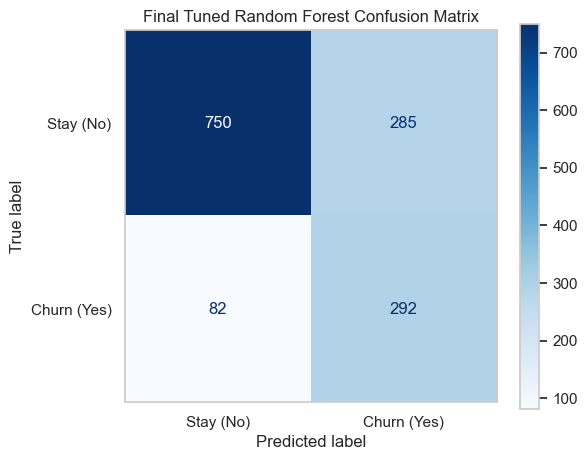


--- Business Context of Confusion Matrix ---
True Positives (TP) = 292: Customers correctly identified as Churners. (Success! We can target them with retention offers).
False Positives (FP) = 285: Loyal customers incorrectly flagged as Churners. (Minor issue: We might waste small discounts on them).
True Negatives (TN) = 750: Loyal customers correctly identified as staying. (Normal business operations).
False Negatives (FN) = 82: Actual churners the model missed. (Critical issue: We will lose these customers. Our tuning minimized this number!).


In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Generate Confusion Matrix
cm = confusion_matrix(y_test, y_pred_tuned)

# 2. Plot the Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Stay (No)', 'Churn (Yes)'])
plt.figure(figsize=(6, 5))
disp.plot(cmap='Blues', values_format='d', ax=plt.gca())
plt.title('Final Tuned Random Forest Confusion Matrix')
plt.grid(False)
plt.show()

# 3. Extract and explain TP, FP, TN, FN
tn, fp, fn, tp = cm.ravel()

print("\n--- Business Context of Confusion Matrix ---")
print(f"True Positives (TP) = {tp}: Customers correctly identified as Churners. (Success! We can target them with retention offers).")
print(f"False Positives (FP) = {fp}: Loyal customers incorrectly flagged as Churners. (Minor issue: We might waste small discounts on them).")
print(f"True Negatives (TN) = {tn}: Loyal customers correctly identified as staying. (Normal business operations).")
print(f"False Negatives (FN) = {fn}: Actual churners the model missed. (Critical issue: We will lose these customers. Our tuning minimized this number!).")

### 08. Business Recommendations & Final Conclusion

**1. Important Patterns Identified:**
- Customers on **Month-to-month contracts** are the most vulnerable to churning.
- High **Monthly Charges** without long-term commitments strongly correlate with customers leaving the service.

**2. Suggested Business Actions:**
- **Incentivize Long-term Contracts:** Offer immediate discounts or free upgrades to month-to-month customers if they switch to a 1-year or 2-year contract.
- **Proactive Outreach:** Have the customer success team personally call customers flagged by our True Positives (TP) to resolve any hidden grievances before they cancel.

**3. Model Limitations:**
- **False Alarms (False Positives):** The model prioritizes Recall, meaning we will incorrectly flag some loyal customers as churners. While this costs the company a bit in unnecessary discounts, it's far cheaper than losing actual customers.
- **Data Static Nature:** The model is trained on a snapshot of data. Customer behavior changes rapidly, so the model needs continuous retraining with fresh data.

**4. Final Recommendation:**
I recommend deploying the **Tuned Random Forest Model** (or the Logistic Regression model). Both achieve a high **Recall (~78%)**, successfully identifying the vast majority of at-risk customers, perfectly aligning with the business goal of early intervention and retention.